<!-- repro-header -->
> **Reproducibility header**
>
> - **Aim:** Extrasomatic (protrusion) RNA proportion per gene and cell type.
> - **Manuscript panels:** ED Fig. 7J (uncorrected input)
> - **Inputs:** `data_annotated_lambda0.5.zarr`
> - **Outputs:** Violin + strip plots per cell type
> - **Environment / kernel:** `troutpy_drvi`
> - Data root: `/lustre/groups/ml01/datasets/projects/2025_sergio_troutpy` (ROIs on Zenodo 10.5281/zenodo.17446348). 


# Computing protrusion (extrasomatic RNA) proportions per cell type

In [1]:
import spatialdata_io
import spatialdata as sd
import troutpy
import scanpy as sc
from spatialdata import SpatialData

import matplotlib
import matplotlib.pyplot as plt
from spatialdata.transformations import get_transformation
import matplotlib.patches as patches
import os
import sys
import numpy as np
import pandas as pd
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
from pathlib import Path

/home/icb/sergio.salas/miniconda3/envs/troutpy_drvi/lib/python3.10/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(


/home/icb/sergio.salas/miniconda3/envs/troutpy_drvi/lib/python3.10/site-packages/xarray_schema/__init__.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound, get_distribution


/home/icb/sergio.salas/miniconda3/envs/troutpy_drvi/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead.
  warnings.warn(msg, FutureWarning)


/home/icb/sergio.salas/miniconda3/envs/troutpy_drvi/lib/python3.10/site-packages/anndata/utils.py:434: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead.
  warnings.warn(msg, FutureWarning)


In [2]:
from troutpy import pl
from troutpy import tl
from troutpy import pp

# Read dataset

In [3]:
# Define base directories
data_dir = Path("/lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/rois/rois/xenium_msbrain_5k")
saving_path = Path("/lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/xenium_msbrain_5k/protrusion_proportions")

Path(saving_path).mkdir(parents=True, exist_ok=True)

# Read spatial data using the / operator for clean path joining
sdata = sd.read_zarr(data_dir / "data_annotated.zarr")

version mismatch: detected: RasterFormatV02, requested: FormatV04


In [4]:
cell_type_key = 'cell_type'

# Extrasomatic (protrusion) RNA quantification per cell type

For each gene and cell type, we compute the proportion of transcripts found outside the cell body
(extrasomatic / protrusion RNA) relative to the intracellular counts, using the `source_score`
contribution scores and the `xrna_metadata` extracellular counts.

Adapted from [computing_extrasomatic_RNA_analysis.ipynb](https://github.com/theislab/troutpy_reproducibility/blob/main/notebooks/4_detailed_analysis/computing_extrasomatic_RNA_analysis.ipynb).

In [5]:
# `source_score` / `target_score` were computed with leiden cluster ids as the cell-type axis
# (see troutpy.tl.compute_target_score(..., celltype_key="leiden") elsewhere in this analysis),
# while `sdata['table'].obs['cell_type']` holds the annotated cell type names. Map leiden -> cell_type
# here so both axes line up when we align matrices below.
if 'leiden' in sdata['table'].obs.columns:
    leiden_to_celltype = dict(zip(sdata['table'].obs['leiden'], sdata['table'].obs['cell_type']))
    for key in ['source_score', 'target_score']:
        if key in sdata.tables:
            sdata[key].var_names = [leiden_to_celltype.get(v, v) for v in sdata[key].var_names]

In [6]:
# Detect transcripts that were geometrically assigned to a cell's segmentation mask but whose
# local expression signature actually points to a different (nearby) cell type -- i.e. RNA that
# diffused out of a cellular protrusion and "spilled into" a neighboring cell's mask rather than
# genuinely being expressed there. tl.flag_intracellular_spillover reuses prob_is_urna /
# closest_cell_type, which troutpy already computes for every transcript (not just extracellular
# ones), instead of running a new expensive neighbor search.
#
# NOTE: these are new functions added to the local troutpy dev source (imported above as the bare
# `tl` module, not the installed `troutpy` package -- see cell 2), so we call them via `tl.*`,
# matching how this notebook already calls other actively-developed functions (e.g.
# `tl.celltype_contact_matrix`) elsewhere in this analysis.
spillover_df = tl.flag_intracellular_spillover(
    sdata,
    prob_threshold=0.5,
    cell_type_col='leiden',  # closest_cell_type is computed at leiden-cluster resolution
)

# Remove flagged spillover transcripts from the receiving cell's raw counts (a new 'decontaminated'
# layer), so intracellular counts used below reflect each cell's own expression rather than
# material picked up from a neighbor's protrusion.
sdata = tl.decontaminate_cell_expression(
    sdata,
    spillover_df,
    expr_key='table',
    layer_key='raw',
    output_layer='decontaminated',
)

Flagged 193122 / 15440195 intracellular transcripts as likely spillover (prob_threshold=0.5).


In [ ]:
### ==== TOOL FUNCTIONS ==== ###

def load_and_prepare_data(sdata):
    expr = sdata['table'].to_df()
    sdata['table'].X = sdata['table'].layers['raw'].todense()
    cell_types = sdata['table'].obs['cell_type']

    xrna_count = sdata['xrna_metadata'].var['count']
    contrib_df = sdata['source_score'].to_df()
    contrib_df['gene'] = sdata['source_score'].obs['gene']

    return expr, cell_types, xrna_count, contrib_df


def compute_contributions(contrib_df):
    contrib_matrix = contrib_df.groupby('gene').sum()
    contrib_norm = contrib_matrix  # optionally normalize here
    return contrib_norm


def compute_extracellular_counts(contrib_norm, xrna_count):
    genes_common = contrib_norm.index.intersection(xrna_count.index)
    return contrib_norm.loc[genes_common], xrna_count.loc[genes_common]


def compute_intracellular_counts(expr, cell_types):
    grouped = expr.groupby(cell_types)
    return grouped.sum().T, grouped.mean().T


def align_matrices(extra, intra, intra_mean):
    genes_final = extra.index.intersection(intra.index)
    celltypes_final = extra.columns.intersection(intra.columns)
    return (
        extra.loc[genes_final, celltypes_final],
        intra.loc[genes_final, celltypes_final],
        intra_mean.loc[genes_final, celltypes_final],
    )


def compute_extracellular_proportion(extra, intra):
    total = extra + intra
    return extra / total


def filter_genes(intra_mean):
    expr_frac = intra_mean.div(intra_mean.sum(axis=1), axis=0) > 0.1
    expr_level = intra_mean > 0.5
    return expr_frac & expr_level


def collect_filtered_data(extra_matrix, intra_matrix, intra_mean, prop_matrix, combined_filter):
    filtered = []
    for cell_type in extra_matrix.columns:
        extra = extra_matrix[cell_type]
        intra_mean_col = intra_mean[cell_type]
        filt = combined_filter[cell_type]
        prop = prop_matrix[cell_type]

        extra = extra[filt]
        intra_mean_col = intra_mean_col[filt]
        prop = prop[filt].fillna(0)

        for gene in extra.index:
            filtered.append({
                'gene': gene,
                'cell_type': cell_type,
                'extracellular_proportion': prop[gene]
            })
    return pd.DataFrame(filtered)

def compute_and_extrasomatic_proportion(
    sdata,
    source_score_key='source_score',
    expr_key='table',
    xrna_key='xrna_metadata',
    layer_key='raw',
    output_key='extrasomatic_proportion_x_cell_type',
    spillover_df=None,
    leiden_to_celltype=None,
):
    """
    Computes and stores extrasomatic (extracellular) proportion per gene per cell type into `sdata`.

    Parameters
    ----------
    sdata : MuData or dict-like
        Input data object containing 'table', 'source_score', and 'xrna_metadata'.
    source_score_key : str
        Key for accessing source scores (default: 'source_score').
    expr_key : str
        Key for accessing expression table (default: 'table').
    xrna_key : str
        Key for accessing xrna_metadata (default: 'xrna_metadata').
    layer_key : str
        Layer from which to extract raw expression values (default: 'raw'). Pass
        'decontaminated' (see tl.decontaminate_cell_expression) to compute
        intracellular counts net of transcripts that spilled in from neighboring cells.
    output_key : str
        Key where the result `AnnData` object will be stored in `sdata`.
    spillover_df : pandas.DataFrame or None
        Output of tl.flag_intracellular_spillover. When given, flagged
        transcripts are credited to their predicted source cell type's extracellular
        tally (tl.credit_spillover_to_source), instead of vanishing once
        removed from the receiving cell via `layer_key='decontaminated'`.
    leiden_to_celltype : dict or None
        Mapping from leiden cluster id to annotated cell type, needed because
        `spillover_df`'s `predicted_true_type` is at leiden resolution (see the
        cell above) while `extra_matrix`'s columns use the annotated cell_type
        vocabulary.

    Returns
    -------
    sdata : updated with `AnnData` object stored at `sdata[output_key]`.
    """

    # 1. Load data
    sdata[expr_key].X = sdata[expr_key].layers[layer_key].todense()
    expr = sdata[expr_key].to_df()
    cell_types = sdata[expr_key].obs['cell_type']

    xrna_count = sdata[xrna_key].var['count']
    contrib_df = sdata[source_score_key].to_df()
    contrib_df['gene'] = sdata[source_score_key].obs['gene']

    # 2. Compute contributions
    contrib_matrix = contrib_df.groupby('gene').sum()
    contrib_matrix = contrib_matrix.T.groupby(level=0).sum().T  # merge cell types that share a name
    contrib_norm = contrib_matrix  # optional: normalize here if needed

    # 3. Compute extracellular counts
    genes_common = contrib_norm.index.intersection(xrna_count.index)
    extra_matrix = contrib_norm.loc[genes_common]
    xrna_count = xrna_count.loc[genes_common]

    # 3b. Credit transcripts that spilled into other cells' segmentation masks back to their
    # predicted true source cell type's extracellular tally. Pairs with `layer_key='decontaminated'`
    # above, which already removed these same transcripts from the receiving cell's intracellular
    # counts -- so the signal moves from "receiver's intracellular expression" to "source cell
    # type's extracellular signal" instead of being double-counted or dropped.
    if spillover_df is not None:
        extra_matrix = tl.credit_spillover_to_source(extra_matrix, spillover_df, leiden_to_celltype)

    # 4. Compute intracellular counts
    grouped = expr.groupby(cell_types)
    intra_matrix = grouped.sum().T
    intra_mean_matrix = grouped.mean().T

    # 5. Align all matrices
    genes_final = extra_matrix.index.intersection(intra_matrix.index)
    celltypes_final = extra_matrix.columns.intersection(intra_matrix.columns)

    extra_matrix = extra_matrix.loc[genes_final, celltypes_final]
    intra_matrix = intra_matrix.loc[genes_final, celltypes_final]
    intra_mean_matrix = intra_mean_matrix.loc[genes_final, celltypes_final]

    # 6. Compute extracellular proportion
    extracellular_proportion = extra_matrix / (extra_matrix + intra_matrix)

    # 7. Save result to AnnData
    extrasomatic_ct = sc.AnnData(extracellular_proportion.transpose())
    extrasomatic_ct.obs['cell_type'] = extrasomatic_ct.obs.index
    extrasomatic_ct.layers['extra_expression'] = extra_matrix.transpose()
    extrasomatic_ct.layers['intra_expression'] = intra_matrix.transpose()
    extrasomatic_ct.layers['intra_mean_expression'] = intra_mean_matrix.transpose()

    # 8. Store in sdata
    sdata[output_key] = extrasomatic_ct

    return sdata


### PLOTTING

def plot_extrasomatic_scatter_per_celltype(
    sdata,
    extrasomatic_key='extrasomatic_proportion_x_cell_type',
    min_expr_mean=0.5,
    min_expr_frac=0.1,
    figsize=(8, 6),
    s=10,
    color='magenta',
    fontsize=10,
    log_x=True,
    saving_path=None,
    save=False
):
    """
    Plots scatter plots per cell type for extracellular proportion vs intracellular expression.
    All data is extracted from `sdata` under the provided `extrasomatic_key`.

    Parameters
    ----------
    sdata : MuData
        Main data container.
    extrasomatic_key : str
        Key to access extrasomatic data (an AnnData) in sdata.
    min_expr_mean : float
        Minimum average intracellular expression to include gene.
    min_expr_frac : float
        Minimum expression fraction (relative) to include gene.
    figsize : tuple
        Figure size.
    s : float
        Size of the scatter plot points.
    color : str
        Color of scatter plot points.
    fontsize : int
        Font size for gene labels.
    log_x : bool
        Whether to apply log scale to x-axis.
    saving_path : str or None
        Path to save figures if `save` is True.
    save : bool
        Whether to save each plot as PDF.
    """

    extrasomatic = sdata[extrasomatic_key]

    # Ensure all matrices are DataFrames with proper labels
    extra_matrix = pd.DataFrame(
        extrasomatic.layers['extra_expression'].T,
        index=extrasomatic.var_names,
        columns=extrasomatic.obs_names
    )

    intra_matrix = pd.DataFrame(
        extrasomatic.layers['intra_expression'].T,
        index=extrasomatic.var_names,
        columns=extrasomatic.obs_names
    )

    intra_mean_matrix = pd.DataFrame(
        extrasomatic.layers['intra_mean_expression'].T,
        index=extrasomatic.var_names,
        columns=extrasomatic.obs_names
    )

    extracellular_proportion = pd.DataFrame(
        extrasomatic.X.T,
        index=extrasomatic.var_names,
        columns=extrasomatic.obs_names
    )

    # Gene filtering
    gene_filter = (
        (intra_mean_matrix > min_expr_mean) &
        (intra_mean_matrix.div(intra_mean_matrix.sum(axis=1), axis=0) > min_expr_frac)
    )

    for cell_type in extra_matrix.columns:
        extra = extra_matrix[cell_type]
        intra_mean_col = intra_mean_matrix[cell_type]
        prop = extracellular_proportion[cell_type]
        filt = gene_filter[cell_type]

        extra = extra[filt]
        intra_mean_col = intra_mean_col[filt]
        prop = prop[filt].fillna(0)

        plt.figure(figsize=figsize)
        plt.scatter(intra_mean_col, prop, alpha=0.6, s=s, color=color)

        for gene, x, y in zip(extra.index, intra_mean_col, prop):
            plt.text(x, y, gene, fontsize=fontsize, alpha=0.7)

        plt.xlabel("Intracellular Expression")
        plt.ylabel("Extracellular Proportion")
        plt.title(f"Extracellular Enrichment in {cell_type}")
        plt.ylim(-0.05, 1.05)
        plt.grid(True, linestyle='--', alpha=0.5)
        if log_x:
            plt.xscale('log')
        plt.tight_layout()

        if save and saving_path:
            os.makedirs(saving_path, exist_ok=True)
            safe_cell_type = str(cell_type).replace('/', '-').replace('\\', '-')
            out_path = os.path.join(saving_path, f"scatter_{safe_cell_type}_extrasomatic.pdf")
            plt.savefig(out_path)

        plt.show()


def plot_violin_of_extrasomatic_proportion(
    sdata,
    extrasomatic_key='extrasomatic_proportion_x_cell_type',
    table_key='table',
    n=1,
    min_expr_mean=0.5,
    min_expr_frac=0.1,
    figsize=(7, 7), s=1,
    saving_path=None,
    save=False
):
    """
    Plot violin + stripplot of extracellular proportions per cell type from `sdata`.

    Parameters
    ----------
    sdata : MuData or dict-like
        Data structure containing the computed extracellular proportions.
    extrasomatic_key : str
        Key where the extrasomatic AnnData is stored in sdata.
    table_key : str
        Key for accessing cell type colors and cell type labels.
    n : int
        Number of top/bottom genes to annotate per cell type.
    min_expr_mean : float
        Minimum average intracellular expression to include gene.
    min_expr_frac : float
        Minimum fraction of expression per cell type to include gene.
    figsize : tuple
        Figure size for the plot.
    saving_path : str or None
        If provided and `save=True`, plot will be saved here.
    s: float
        Size of the dots in the stripplot
    save : bool
        Whether to save the plot to PDF.
    """

    extrasomatic = sdata[extrasomatic_key]

    # Ensure all layers and matrices are DataFrames with proper labels
    extra_matrix = pd.DataFrame(
        extrasomatic.layers['extra_expression'].T,
        index=extrasomatic.var_names,
        columns=extrasomatic.obs_names
    )

    intra_matrix = pd.DataFrame(
        extrasomatic.layers['intra_expression'].T,
        index=extrasomatic.var_names,
        columns=extrasomatic.obs_names
    )

    intra_mean_matrix = pd.DataFrame(
        extrasomatic.layers['intra_mean_expression'].T,
        index=extrasomatic.var_names,
        columns=extrasomatic.obs_names
    )

    extracellular_proportion = pd.DataFrame(
        extrasomatic.X.T,
        index=extrasomatic.var_names,
        columns=extrasomatic.obs_names
    )

    # Apply filters
    gene_filter = (
        (intra_mean_matrix > min_expr_mean) &
        (intra_mean_matrix.div(intra_mean_matrix.sum(axis=1), axis=0) > min_expr_frac)
    )

    filtered_data = []
    for cell_type in extra_matrix.columns:
        extra = extra_matrix[cell_type]
        intra_mean_col = intra_mean_matrix[cell_type]
        prop = extracellular_proportion[cell_type]
        filt = gene_filter[cell_type]

        extra = extra[filt]
        intra_mean_col = intra_mean_col[filt]
        prop = prop[filt].fillna(0)

        for gene in extra.index:
            filtered_data.append({
                'gene': gene,
                'cell_type': cell_type,
                'extracellular_proportion': prop[gene]
            })

    filtered_df = pd.DataFrame(filtered_data)

    # Order cell types by mean extracellular proportion
    order_ct = (
        filtered_df
        .groupby('cell_type')['extracellular_proportion']
        .mean()
        .sort_values(ascending=False)
        .index
    )

    # Use color dictionary from sdata
    coldict = dict(zip(
        np.unique(sdata[table_key].obs['cell_type']),
        sdata[table_key].uns['cell_type_colors']
    ))
    cols = [coldict[c] for c in order_ct]

    # Plot
    # Set font type for vector output
    matplotlib.rcParams['pdf.fonttype'] = 42
    matplotlib.rcParams['ps.fonttype'] = 42
    plt.figure(figsize=figsize, dpi=100)
    ax = sns.violinplot(
        data=filtered_df,
        y='cell_type',
        x='extracellular_proportion',
        order=order_ct,
        alpha=0.8,
        linewidth=0,
        palette=cols,
        inner=None
    )

    sns.stripplot(
        data=filtered_df,
        y='cell_type',
        x='extracellular_proportion',
        color='gray',
        s=s,
        order=order_ct,
        jitter=0.3,
        linewidth=0.01,
        ax=ax
    )

    for cell_type in order_ct:
        df_sub = filtered_df[filtered_df['cell_type'] == cell_type]

        # Top n
        top_n = df_sub.nlargest(n, 'extracellular_proportion')
        for _, row in top_n.iterrows():
            ax.text(row['extracellular_proportion'], cell_type, row['gene'],
                    color='#bf1324', fontsize=10, va='bottom', ha='left')

        # Bottom n
        bottom_n = df_sub.nsmallest(n, 'extracellular_proportion')
        for _, row in bottom_n.iterrows():
            ax.text(row['extracellular_proportion'], cell_type, row['gene'],
                    color='#3d57ad', fontsize=10, va='bottom', ha='right')

    plt.xlabel('Extrasomatic Proportion')
    plt.ylabel('Cell Type')
    plt.tight_layout()

    if save and saving_path:
        os.makedirs(saving_path, exist_ok=True)
        out_path = os.path.join(saving_path, 'cells_extracellular_proportion.pdf')
        plt.savefig(out_path)

    plt.show()

In [ ]:
sdata = compute_and_extrasomatic_proportion(
    sdata,
    layer_key='decontaminated',
    spillover_df=spillover_df,
    leiden_to_celltype=leiden_to_celltype,
)

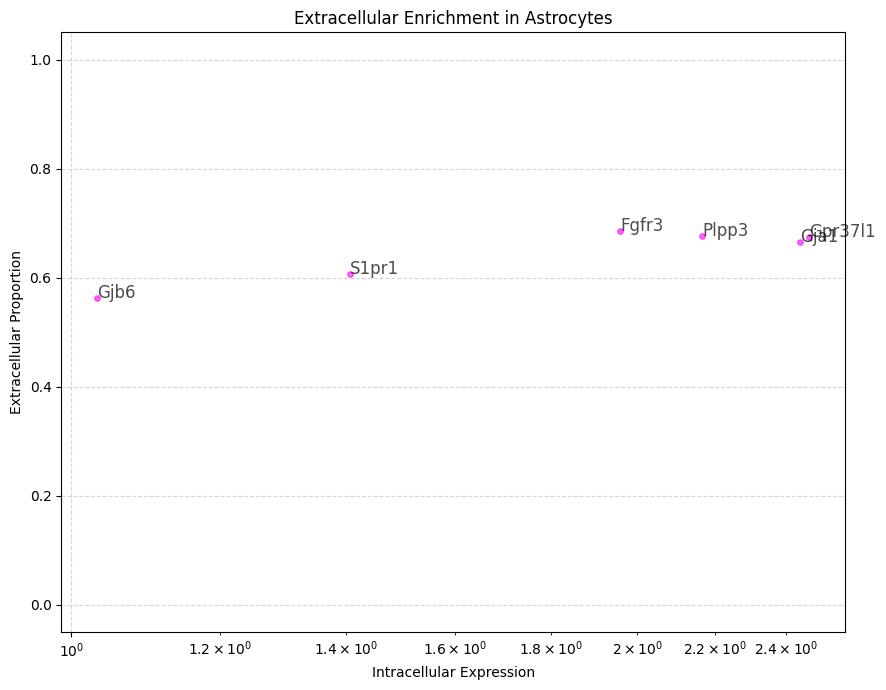

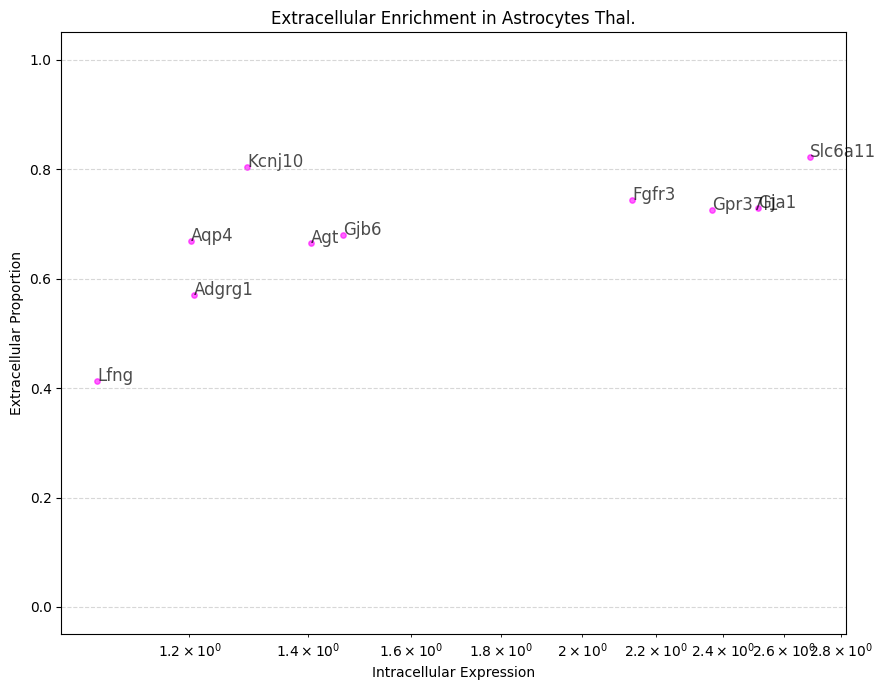

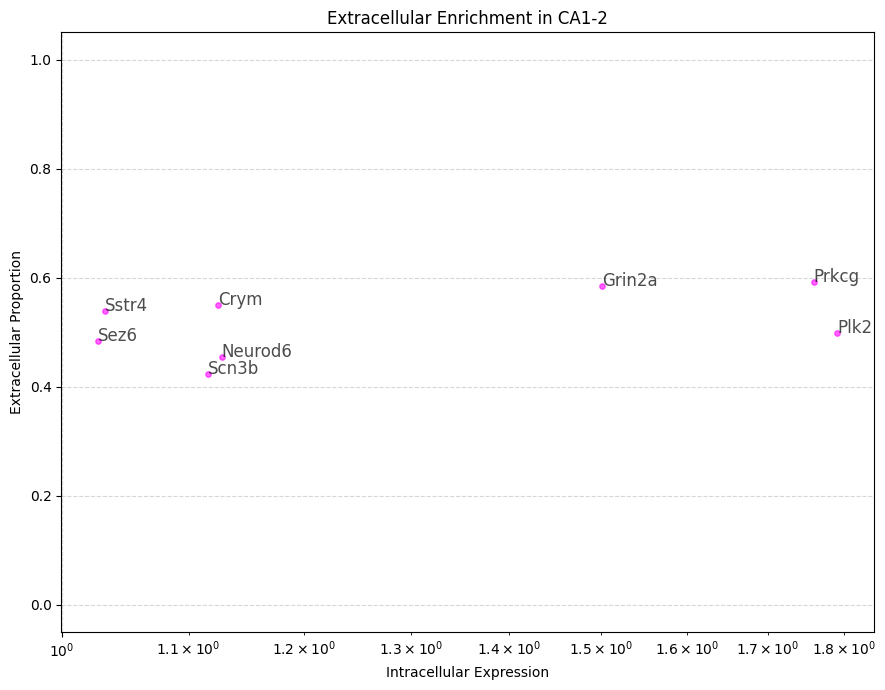

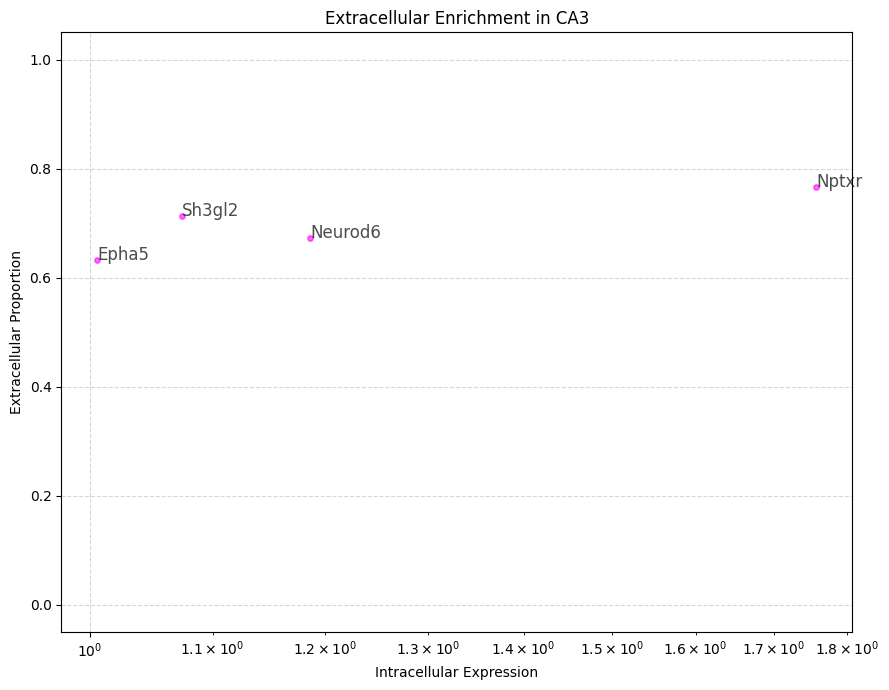

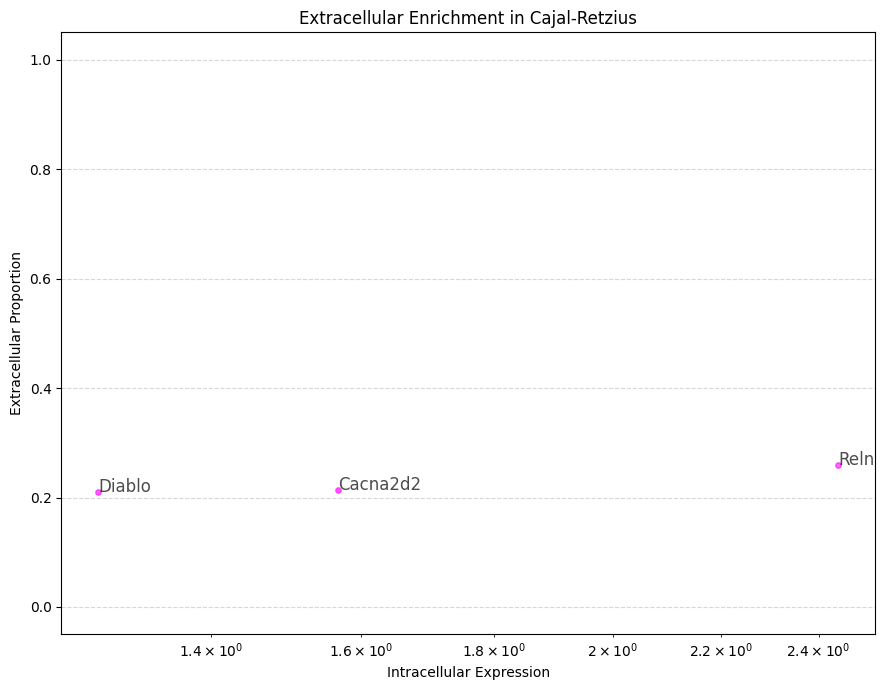

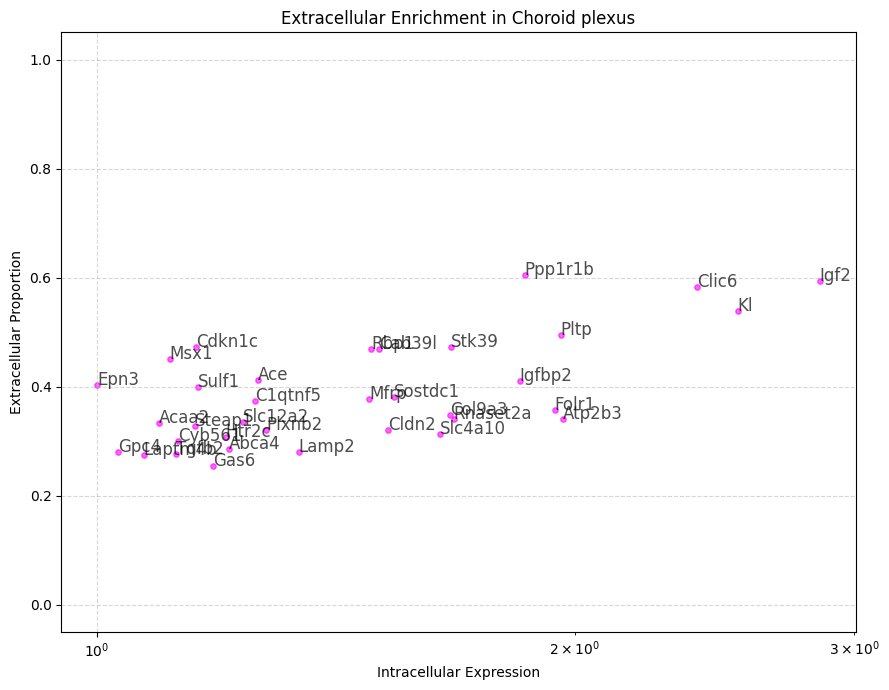

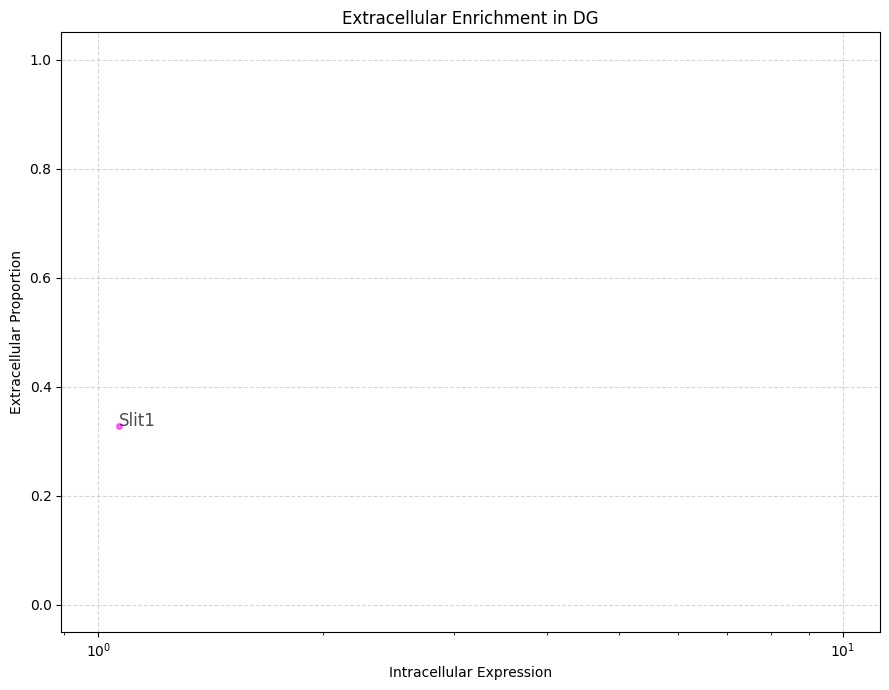

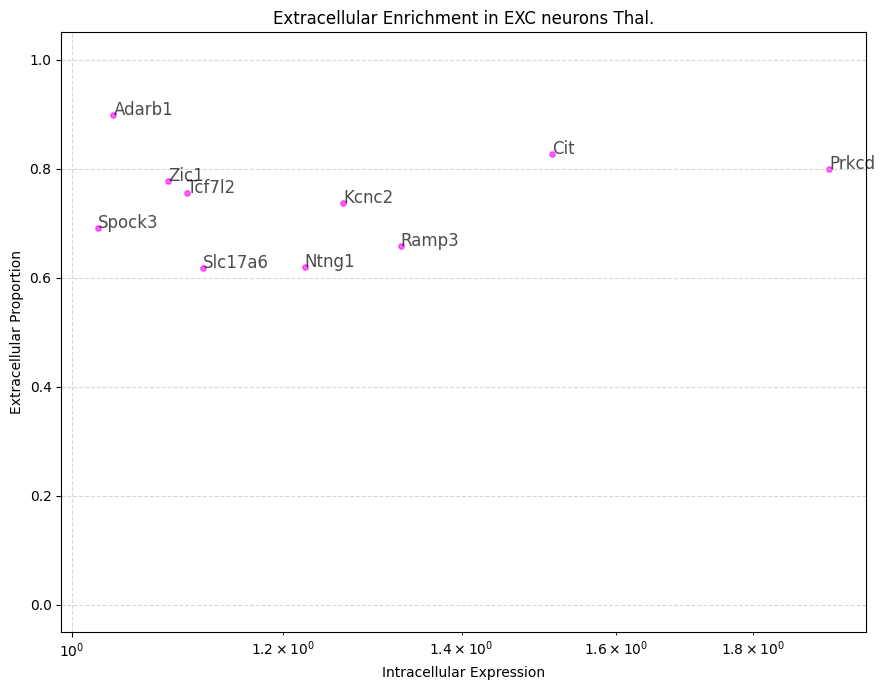

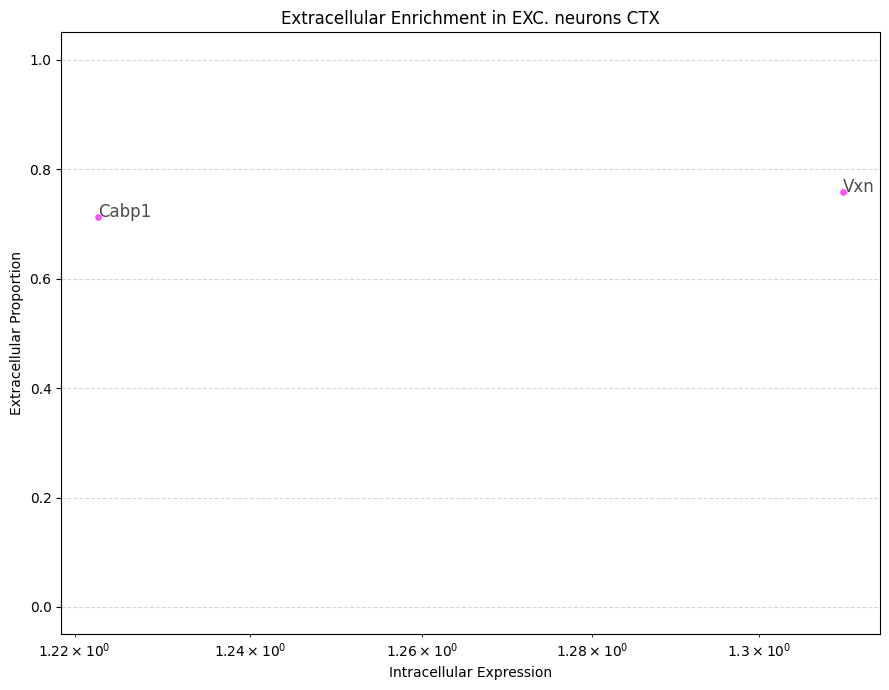

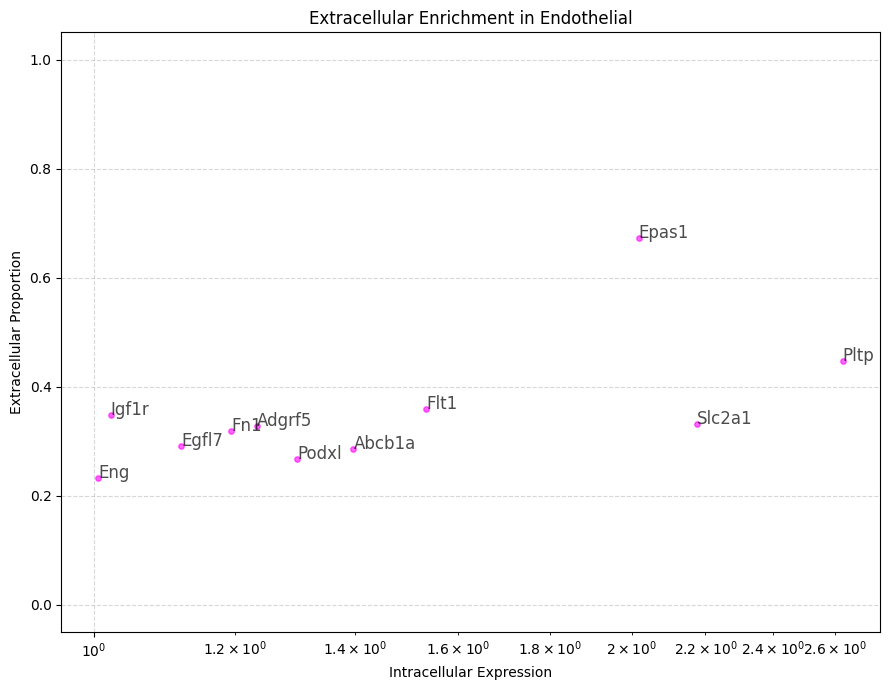

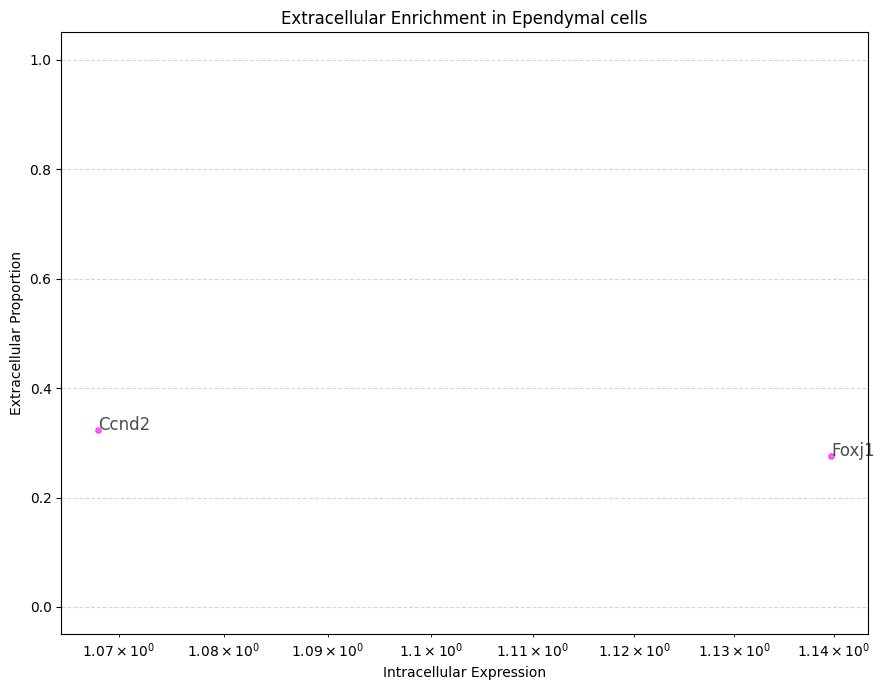

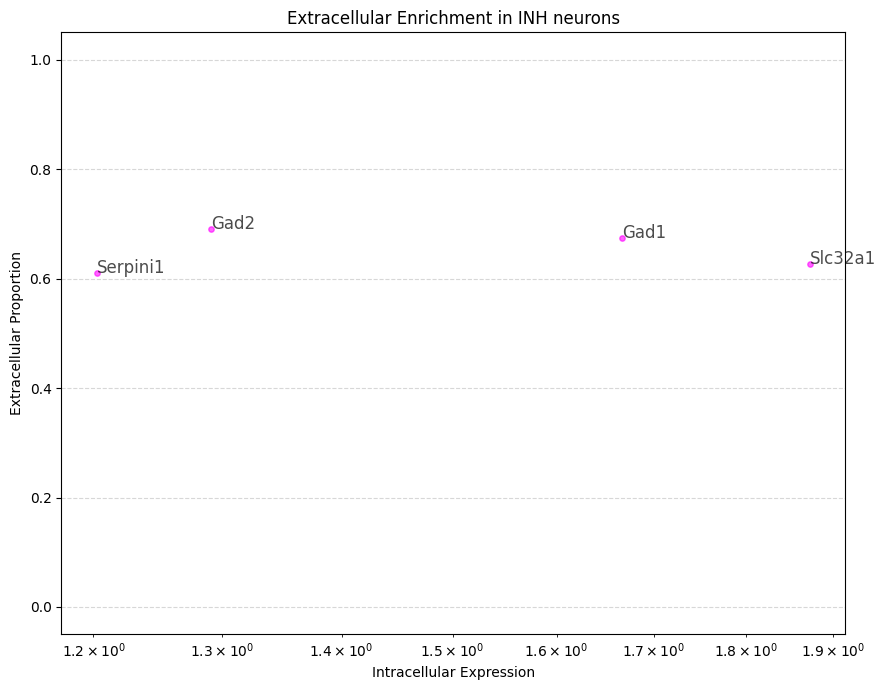

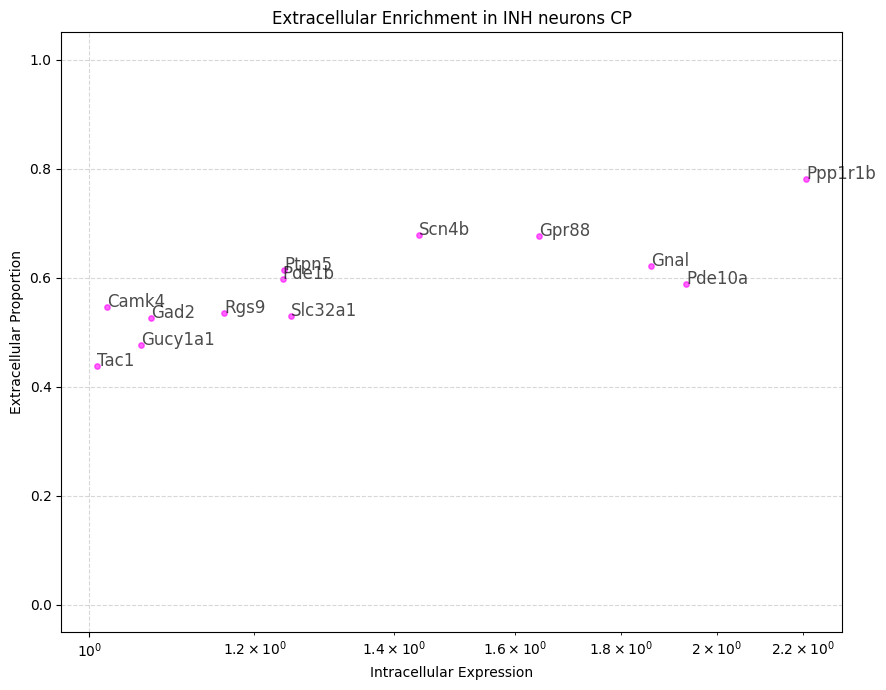

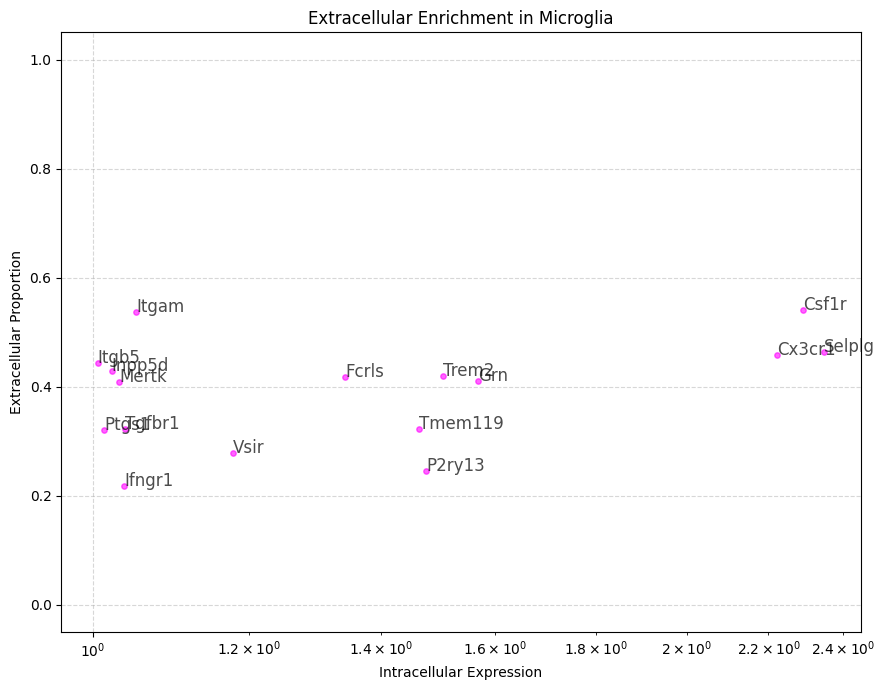

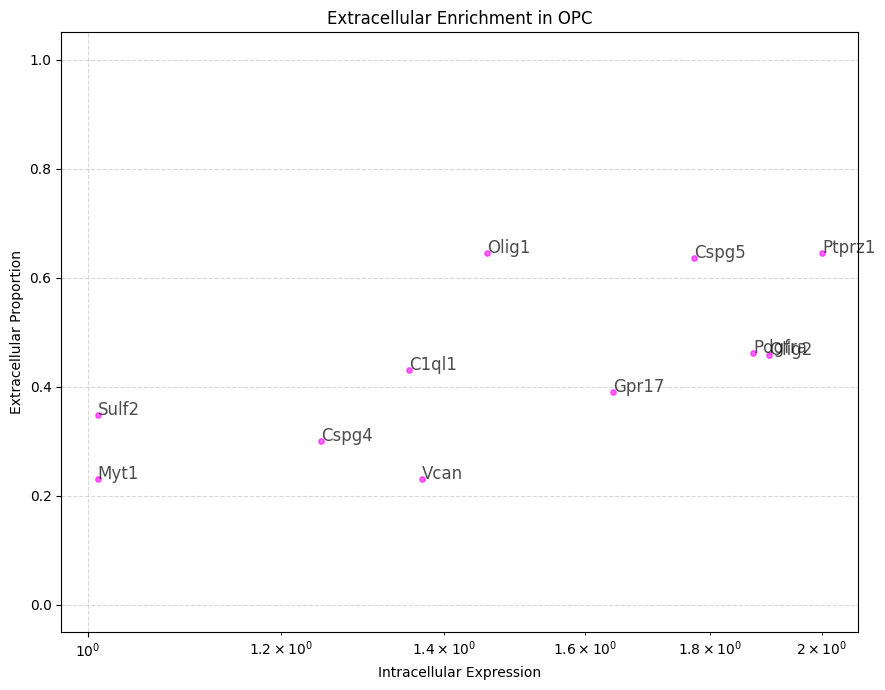

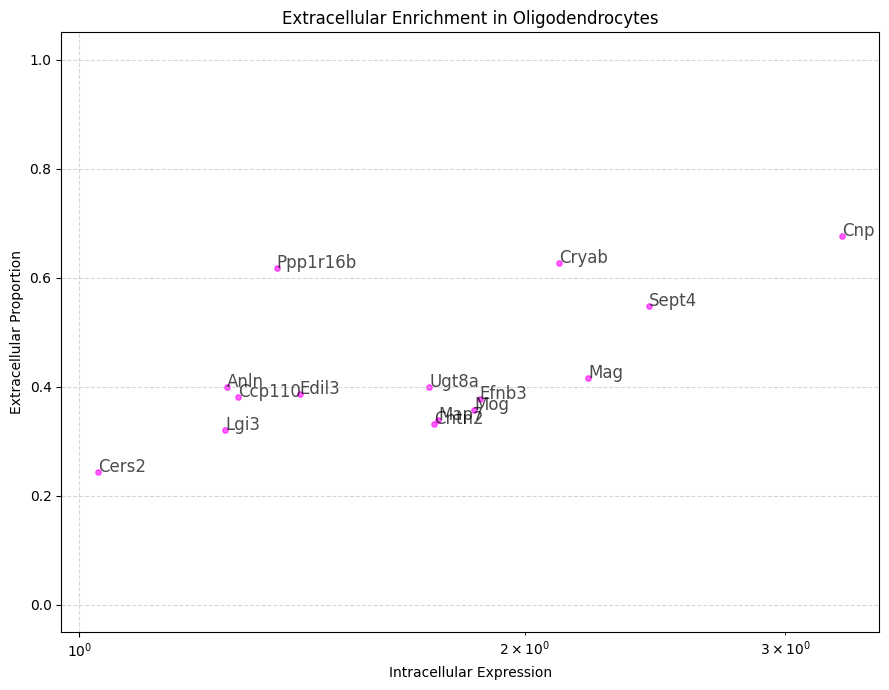

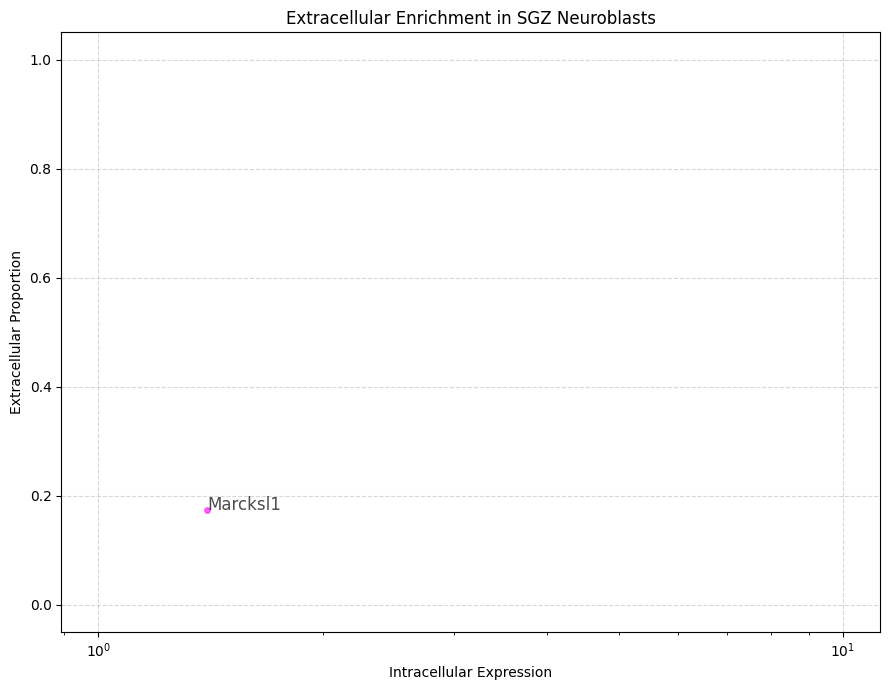

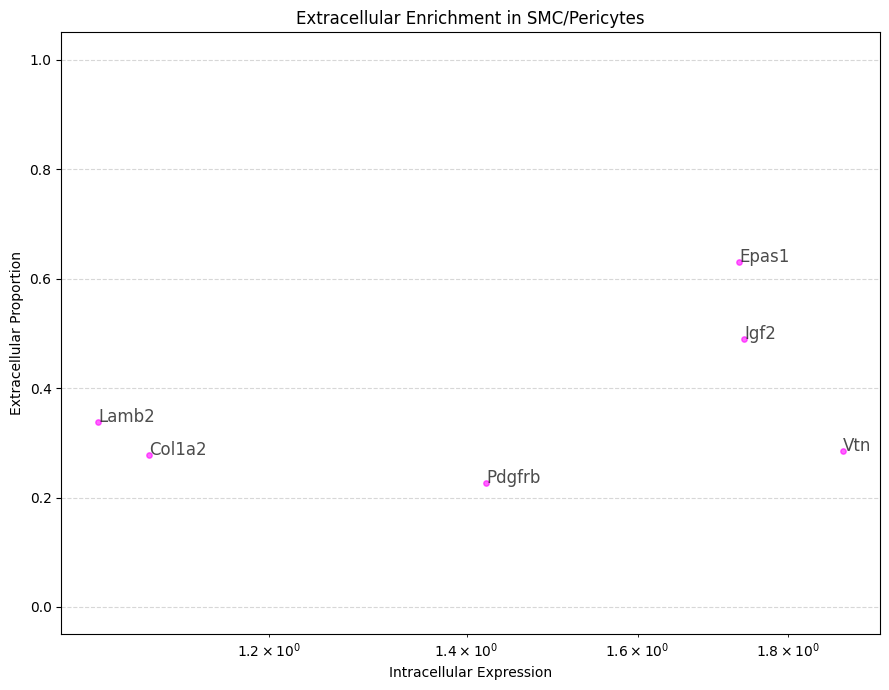

In [8]:
plot_extrasomatic_scatter_per_celltype(
    sdata,
    min_expr_mean=1,
    min_expr_frac=0.2,
    color='magenta',
    s=15,
    fontsize=12,
    figsize=(9, 7),
    log_x=True,
    saving_path=saving_path,
    save=True
)

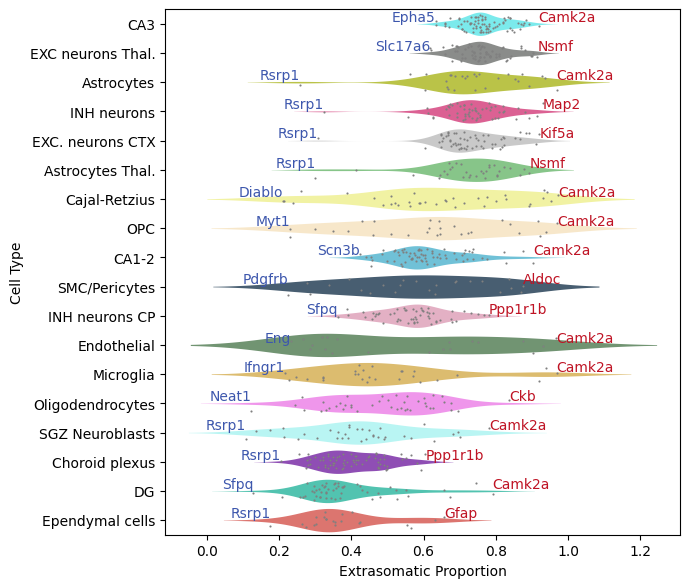

In [9]:
plot_violin_of_extrasomatic_proportion(
    sdata,
    n=1,
    min_expr_mean=1,
    min_expr_frac=0.05,
    s=1.5,
    figsize=(7, 6),
    saving_path=saving_path,
    save=True
)